## Radiology Clinic Bookings Analysis
### Introduction

### Project Overview
Radiology clinics run on a mix of high-volume, low-cost scans such as X-ray and Ultrasound, and low-volume, high-value scans such as CT and MRI. Booking volume alone does not show where the money is made, which branches are underperforming, or where patients wait too long for their results.
This project analyses two years of booking data (January 2024 to December 2025) from a radiology clinic with seven branches across Kenya: Nairobi, Mombasa, Kisumu, Nakuru, Eldoret, Thika and Kisii. Each record is one scan booking, with the patient’s age and gender, the branch, the type of scan, how the patient paid, how they were referred, the price in Kenya Shillings (KES) and the turnaround time in hours


### Business Problem
Clinic management needs to know which services and locations drive revenue, where operations are slow, and where to invest or improve. The raw data is messy, as real clinic data usually is, with inconsistent spellings, mixed date formats, placeholder values such as UNKNOWN and ERROR, impossible ages, zero prices and duplicate bookings. It has to be cleaned before any reliable conclusion can be drawn.

### Objectives
The project aims to answer the questions a clinic manager would actually ask:
•	Which scan types and branches bring in the most bookings and the most revenue?
•	Is revenue growing, and is there any seasonality in demand?
•	Which branches and scan types have the slowest turnaround time?
•	How do cash and insurance patients differ?
•	What actually drives the price of a booking?


### Approach
The analysis is done in Python in a Jupyter Notebook. It starts with data quality checks and cleaning, then adds new features such as scan month, weekend flag and age group. It then answers specific business questions, explores patterns with charts and interactive Plotly visuals, and builds a linear regression model to predict the price of a booking. The results are turned into practical recommendations for clinic management.
Tools: Python, pandas, NumPy, Matplotlib, Seaborn, Plotly and scikit-learn.


In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import plotly.express as px
import plotly.graph_objects as go


# Machine learning libraries scikitlearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
# Load the dataset
df = pd.read_csv("data/radiology_clinic_bookings.csv")

In [3]:
# preview the data
df.head()

,booking_id,patient_id,branch,scan_date,modality,age,gender,payment_type,referral_source,price_kes,turnaround_hours
0,B206573,P100114,Nairobi,2025-04-25,Ultrasound,35.0,Male,Cash,Doctor Referral,2300.0,4.9
1,B204617,P103409,kisii,11-30-2024,X-ray,14.0,Female,Cash,Self,NaN,0.8
2,B205216,P104694,Nairobi,2025-01-14,X-ray,NaN,Male,Cash,Doctor Referral,1620.0,4.5
3,B200194,P102262,Nairobi,2024-01-16,X-ray,13.0,Female,Cash,Doctor Referral,2700.0,1.2
4,B209549,P109974,nairobi,2025-11-29,MRI,NaN,Male,Cash,Corporate/Insurance Scheme,32180.0,25.7


In [4]:
# the last 5 rows
df.tail()

,booking_id,patient_id,branch,scan_date,modality,age,gender,payment_type,referral_source,price_kes,turnaround_hours
10140,B206400,P102972,Mombasa,2025-04-13,CT Scan,23.0,Female,Insurance,Self,19940.0,16.4
10141,B209160,P103936,Kisii,2025-10-31,ultrasound,72.0,male,Insurance,Corporate/Insurance Scheme,2480.0,6.5
10142,B209859,P101177,Eldoret,2025-12-22,X-ray,62.0,Male,Cash,Self,2140.0,6.6
10143,B201688,P107679,Mombasa,2024-05-01,Ultrasound,14.0,Male,Cash,Self,3360.0,4.4
10144,B205994,P101980,Mombasa,2025-03-16,CT Scan,63.0,Male,Cash,Hospital Transfer,11290.0,20.9


In [5]:
# sample of the data
df.sample(10)

,booking_id,patient_id,branch,scan_date,modality,age,gender,payment_type,referral_source,price_kes,turnaround_hours
7487,B206830,P101270,MOMBASA,12/05/2025,X-ray,33.0,Male,Cash,Hospital Transfer,2660.0,4.1
8201,B207043,P109888,Nakuru,2025-05-29,X-ray,63.0,Male,Insurance,Self,1760.0,7.0
9463,B200336,P104143,Mombasa,2024-01-27,Mammography,35.0,Female,Cash,Self,4800.0,2.5
2670,B206237,P101726,Nairobi,2025-04-02,Ultrasound,35.0,Male,Cash,Corporate/Insurance Scheme,3630.0,6.1
3874,B203834,P101545,Mombasa,2024-10-04,MRI,53.0,Female,Cash,NaN,18900.0,33.1
7082,B208403,P102062,Nairobi,2025-09-05,x-ray,46.0,F,Cash,Corporate/Insurance Scheme,1470.0,3.3
2328,B207798,P105866,Mombasa,2025-07-23,X-ray,18.0,Male,Cash,Doctor Referral,2830.0,0.5
3667,B202395,P103662,mombasa,2024-06-20,Ultrasound,12.0,Male,Cash,Hospital Transfer,3010.0,4.0
7601,B203094,P108933,Kisii,2024-08-10,CT Scan,44.0,Male,Insurance,Doctor Referral,14480.0,25.9
5485,B208746,P102394,Nairobi,2025-09-30,MRI,46.0,Male,Insurance,Doctor Referral,13990.0,25.8


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10145 entries, 0 to 10144
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   booking_id        10145 non-null  str    
 1   patient_id        10145 non-null  str    
 2   branch            10145 non-null  str    
 3   scan_date         10145 non-null  str    
 4   modality          10145 non-null  str    
 5   age               9739 non-null   float64
 6   gender            9943 non-null   str    
 7   payment_type      9838 non-null   str    
 8   referral_source   9432 non-null   str    
 9   price_kes         9994 non-null   float64
 10  turnaround_hours  9888 non-null   float64
dtypes: float64(3), str(8)
memory usage: 1.4 MB


In [7]:
# statistical summary of the data
df.describe()

,age,price_kes,turnaround_hours
count,9739.000000,9994.000000,9888.000000
mean,42.761372,7169.952972,10.385770
std,31.642634,7433.984250,10.461502
min,-1.000000,0.000000,0.500000
25%,29.500000,2240.000000,3.300000
50%,43.000000,3230.000000,5.200000
75%,54.000000,11500.000000,17.700000
max,999.000000,33150.000000,49.500000


In [8]:
# check the datatypes
df.dtypes

booking_id              str
patient_id              str
branch                  str
scan_date               str
modality                str
age                 float64
gender                  str
payment_type            str
referral_source         str
price_kes           float64
turnaround_hours    float64
dtype: object

#### Data Quality

In [9]:
# Check for missing values
df.isnull().sum()

booking_id            0
patient_id            0
branch                0
scan_date             0
modality              0
age                 406
gender              202
payment_type        307
referral_source     713
price_kes           151
turnaround_hours    257
dtype: int64

In [10]:
df.isna().sum()

booking_id            0
patient_id            0
branch                0
scan_date             0
modality              0
age                 406
gender              202
payment_type        307
referral_source     713
price_kes           151
turnaround_hours    257
dtype: int64

In [11]:
# Duplicate records in the dataset
df.duplicated().sum()

np.int64(87)

# Data Cleaning
## Cleaning order
### 1.Hidden errors 'UNKNOWN' & 'ERROR'
### 2.Fix data Types
### 3.Drop Missing values

In [12]:
# Remove hidden errors in the dataset
invalid_values = ['UNKNOWN', 'ERROR', 'N/A', '?']

#Replace the invalid values with NaN(missing value) 
df.replace(invalid_values, np.nan, inplace=True)

,booking_id,patient_id,branch,scan_date,modality,age,gender,payment_type,referral_source,price_kes,turnaround_hours
0,B206573,P100114,Nairobi,2025-04-25,Ultrasound,35.0,Male,Cash,Doctor Referral,2300.0,4.9
1,B204617,P103409,kisii,11-30-2024,X-ray,14.0,Female,Cash,Self,NaN,0.8
2,B205216,P104694,Nairobi,2025-01-14,X-ray,NaN,Male,Cash,Doctor Referral,1620.0,4.5
3,B200194,P102262,Nairobi,2024-01-16,X-ray,13.0,Female,Cash,Doctor Referral,2700.0,1.2
4,B209549,P109974,nairobi,2025-11-29,MRI,NaN,Male,Cash,Corporate/Insurance Scheme,32180.0,25.7
...,...,...,...,...,...,...,...,...,...,...,...
10140,B206400,P102972,Mombasa,2025-04-13,CT Scan,23.0,Female,Insurance,Self,19940.0,16.4
10141,B209160,P103936,Kisii,2025-10-31,ultrasound,72.0,male,Insurance,Corporate/Insurance Scheme,2480.0,6.5
10142,B209859,P101177,Eldoret,2025-12-22,X-ray,62.0,Male,Cash,Self,2140.0,6.6
10143,B201688,P107679,Mombasa,2024-05-01,Ultrasound,14.0,Male,Cash,Self,3360.0,4.4


In [13]:
# Recheck for missing values after replacing invalid values
df.isnull().sum()

booking_id            0
patient_id            0
branch                0
scan_date             0
modality              0
age                 406
gender              202
payment_type        307
referral_source     713
price_kes           151
turnaround_hours    257
dtype: int64

In [14]:
# Fixing the datatypes of the columns
df['scan_date'] = pd.to_datetime(df['scan_date'], errors='coerce')
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['gender'] = df['gender'].astype('category')
df['branch'] = df['branch'].astype('category')
df['modality'] = df['modality'].astype('category')
df['payment_type'] = df['payment_type'].astype('category')
df['referral_source'] = df['referral_source'].astype('category')
df['patient_id'] = df['patient_id'].astype('category')
df['booking_id'] = df['booking_id'].astype('category')

In [15]:
# Fixing the age values that are less than 0 or greater than 110 by replacing them with NaN
df.loc[(df['age'] < 0) | (df['age'] > 110), 'age'] = np.nan
df['age'].describe()

count    9723.000000
mean       42.113442
std        18.502267
min         0.000000
25%        30.000000
50%        43.000000
75%        54.000000
max        95.000000
Name: age, dtype: float64

In [16]:
# fixing the invalid price entries
df.loc[df['price_kes'] == 0, 'price_kes'] = np.nan

In [17]:
# Standardizing the text data in the columns
df['branch'] = df['branch'].str.strip().str.title()
df['modality'] = df['modality'].str.strip().str.lower().map({
    'x-ray':'X-ray','xray':'X-ray','x ray':'X-ray',
    'ultrasound':'Ultrasound','us':'Ultrasound','ultra sound':'Ultrasound',
    'ct scan':'CT Scan','ct':'CT Scan','ctscan':'CT Scan',
    'mri':'MRI','m.r.i':'MRI',
    'mammography':'Mammography','mammo':'Mammography'
})
df['gender'] = df['gender'].str.strip().str.lower().map({'m':'Male','male':'Male','f':'Female','female':'Female'})

In [18]:
# Applying the changes to the datatypes after text cleaning and standardization
df['branch'] = df['branch'].astype('category')
df['modality'] = df['modality'].astype('category')
df['gender'] = df['gender'].astype('category')

In [19]:
# Check for duplicate records based on the booking_id column
df[df.duplicated(subset='booking_id', keep=False)].sort_values('booking_id')

,booking_id,patient_id,branch,scan_date,modality,age,gender,payment_type,referral_source,price_kes,turnaround_hours
6433,B200032,P108804,Kisumu,2024-01-03,Ultrasound,37.0,Male,Cash,Hospital Transfer,3420.0,2.763586
9999,B200032,P108804,Kisumu,2024-01-03,Ultrasound,37.0,Male,Cash,Hospital Transfer,3420.0,2.400000
3499,B200130,P107454,Nairobi,2024-01-11,X-ray,39.0,Male,Cash,Self,1930.0,3.100000
9361,B200130,P107454,Nairobi,2024-01-11,X-ray,39.0,Male,Cash,Self,1930.0,3.100000
3591,B200218,P108865,Kisumu,NaT,CT Scan,53.0,Female,Cash,Self,20950.0,18.100000
...,...,...,...,...,...,...,...,...,...,...,...
5220,B209887,P100693,Kisii,2025-12-24,CT Scan,42.0,Male,Cash,NaN,9350.0,30.900000
2910,B209953,P109466,Eldoret,2025-12-29,MRI,57.0,Female,Cash,Doctor Referral,21420.0,21.300000
8529,B209953,P109466,Eldoret,2025-12-29,MRI,57.0,Female,Cash,Doctor Referral,21420.0,21.300000
5824,B209984,P104485,Kisumu,2025-12-31,X-ray,15.0,Female,Cash,Hospital Transfer,1360.0,2.700000


In [20]:
# Drop missing values from the dataset
df = df.dropna()

In [21]:
# Drop duplicates
df = df.drop_duplicates()

In [22]:
# Drop duplicates based on the booking_id column, keeping the first occurrence
df = df.drop_duplicates(subset='booking_id', keep='first')

## Validation

In [23]:
# Recheck for missing values after cleaning the dataset
df.isnull().sum()

booking_id          0
patient_id          0
branch              0
scan_date           0
modality            0
age                 0
gender              0
payment_type        0
referral_source     0
price_kes           0
turnaround_hours    0
dtype: int64

In [24]:
# Recheck for duplicates after cleaning the dataset
df.duplicated().sum()

np.int64(0)

In [25]:
# Dataset shape
df.shape

(6931, 11)

In [26]:
# Check datatypes after cleaning
df.dtypes

booking_id                category
patient_id                category
branch                    category
scan_date           datetime64[us]
modality                  category
age                        float64
gender                    category
payment_type              category
referral_source           category
price_kes                  float64
turnaround_hours           float64
dtype: object

In [27]:
# Summary of statistics
df.describe()

,scan_date,age,price_kes,turnaround_hours
count,6931,6931.000000,6931.000000,6931.000000
mean,2024-12-27 15:55:17.443370,42.148463,7213.716635,10.377738
min,2024-01-01 00:00:00,0.000000,1080.000000,0.500000
25%,2024-06-26 12:00:00,30.000000,2240.000000,3.300000
50%,2024-12-24 00:00:00,43.000000,3240.000000,5.200000
75%,2025-06-29 00:00:00,54.000000,11630.000000,17.700000
max,2025-12-31 00:00:00,95.000000,33150.000000,49.500000
std,NaN,18.415864,7479.583079,10.460764


## Feature Engineering

In [28]:
df['scan_year'] = df['scan_date'].dt.year
df['scan_month'] = df['scan_date'].dt.month_name()
df['scan_day_of_week'] = df['scan_date'].dt.day_name()
df['is_weekend'] = df['scan_date'].dt.dayofweek.isin([5, 6])

In [29]:
# Create age groups for analysis
df['age_group'] = pd.cut(
    df['age'],
    bins=[-1, 12, 19, 35, 50, 65, 110],
    labels=[
        'Child', 'Teen', 'Young Adult',
        'Adult', 'Senior', 'Elderly'
    ]
)

In [30]:
# create 'season' based on arrival month
month_to_season = {
    'December': 'Winter', 'January': 'Winter', 'February': 'Winter', 'March': 'Spring', 'April': 'Spring', 'May': 'Spring', 'June': 'Summer', 'July': 'Summer', 'August': 'Summer', 'September': 'Fall', 'October': 'Fall', 'November': 'Fall'
} 

df['season'] = df['scan_month'].map(month_to_season)

In [31]:
# is this booking priced above/below its modality's norm
df['price_per_modality_avg'] = df.groupby('modality')['price_kes'].transform('mean')
df['price_vs_avg'] = df['price_kes'] - df['price_per_modality_avg']  

## Business Questions

In [32]:
# Which modality brings in the most bookings?
df['modality'].value_counts().idxmax() 

'X-ray'

In [33]:
# Which modality brings in the most revenue?
df.groupby('modality')['price_kes'].sum().sort_values().idxmax()


'CT Scan'

In [34]:
# What's the revenue-per-booking for each modality, and how does that change your view of which service is worth expanding?
df.groupby('modality')['price_kes'].mean().sort_values(ascending=False)

modality
MRI            21980.735294
CT Scan        13951.991342
Mammography     4396.481994
Ultrasound      3193.274520
X-ray           2041.769766
Name: price_kes, dtype: float64

In [35]:
# Which branch generates the most total revenue 
df.groupby('branch')['price_kes'].sum().sort_values().idxmax()

'Nairobi'

In [36]:
 # Which branch has the most bookings?
df['branch'].value_counts().idxmax()

'Nairobi'

In [37]:
# Is there a branch that's small in volume but high in revenue-per-booking?
df.groupby('branch')['price_kes'].mean().sort_values(ascending=False)

branch
Eldoret    7668.286558
Nakuru     7649.665948
Thika      7427.323651
Kisii      7268.040936
Mombasa    7089.487909
Nairobi    7022.370807
Kisumu     6947.348315
Name: price_kes, dtype: float64

Eldoret 

In [38]:
# How does age distribution differ across modalities?
df.groupby('modality')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
modality,,,,,,,,
CT Scan,1386.0,49.670274,17.078843,0.0,39.0,50.0,60.0,95.0
MRI,816.0,47.268382,16.220272,0.0,36.0,47.0,59.0,95.0
Mammography,361.0,46.218837,9.167532,18.0,40.0,46.0,52.0,78.0
Ultrasound,1927.0,37.138557,17.701136,0.0,24.0,37.0,49.5,95.0
X-ray,2441.0,39.519050,19.492510,0.0,26.0,39.0,52.0,95.0


Age distribution differs considerably across modalities.

CT Scan has the highest average age, while Ultrasound has the lowest. 

Mammography has the most restricted age range, which is expected because it is primarily associated with breast screening and diagnosis in adults. 

Ultrasound and X-ray serve a much broader range of patients, including very young patients.

In [39]:
# What % of revenue comes from insurance vs. cash, overall and per modality?
df.groupby('payment_type')['price_kes'].sum().sort_values(ascending=False)

payment_type
Insurance    26476830.0
Cash         23521440.0
Name: price_kes, dtype: float64

In [40]:
df.groupby(['modality', 'payment_type'])['price_kes'].sum().sort_values(ascending=False)

modality     payment_type
CT Scan      Insurance       11551910.0
MRI          Insurance       10359520.0
CT Scan      Cash             7785550.0
MRI          Cash             7576760.0
Ultrasound   Cash             3906420.0
X-ray        Cash             3181260.0
Ultrasound   Insurance        2247020.0
X-ray        Insurance        1802700.0
Mammography  Cash             1071450.0
             Insurance         515680.0
Name: price_kes, dtype: float64

In [41]:
(df.groupby('payment_type')['price_kes'].sum() / df['price_kes'].sum() * 100).round(1)

payment_type
Cash         47.0
Insurance    53.0
Name: price_kes, dtype: float64

In [42]:
# Is there a relationship between turnaround time and modality and does that correlate with cash vs. insurance patients?
df.groupby(['modality', 'payment_type'])['turnaround_hours'].mean().sort_values(ascending=False)

modality     payment_type
MRI          Insurance       24.453436
CT Scan      Insurance       24.257710
MRI          Cash            23.607548
CT Scan      Cash            23.577902
Ultrasound   Insurance        4.106423
Mammography  Cash             4.066525
Ultrasound   Cash             4.033503
Mammography  Insurance        4.002400
X-ray        Cash             3.985432
             Insurance        3.957537
Name: turnaround_hours, dtype: float64

There is a strong difference in turnaround time by modality. MRI and CT scans take roughly 24 hours, while Ultrasound, Mammography, and X-ray take only about 4 hours.

The difference between cash and insurance patients is relatively small within each modality, suggesting that the type of imaging modality has a much stronger relationship with turnaround time than payment type.

In [43]:
# Which branch has the slowest average turnaround?
df.groupby('branch')['turnaround_hours'].mean().sort_values(ascending=False)

branch
Nakuru     10.872785
Eldoret    10.773657
Kisii      10.561988
Thika      10.497303
Nairobi    10.383617
Mombasa    10.035739
Kisumu      9.950540
Name: turnaround_hours, dtype: float64

Nakuru

In [44]:
# Which modality has the slowest average turnaround?
df.groupby('modality')['turnaround_hours'].mean().idxmax()

'MRI'

In [45]:
# Has monthly revenue grown, dropped, or stayed flat across 2024–2025?
# Yearly revenue trend

yearly_revenue = df.groupby(df['scan_date'].dt.to_period('Y'))['price_kes'].sum()
print(yearly_revenue)


scan_date
2024    25628670.0
2025    24369600.0
Freq: Y-DEC, Name: price_kes, dtype: float64


Yearly revenue has dropped from 2024 to 2025

In [46]:
# Monthly revenue trend
monthly_revenue = df.groupby(df['scan_date'].dt.to_period('M'))['price_kes'].sum().sort_index()
print(monthly_revenue)

scan_date
2024-01    2003770.0
2024-02    2094760.0
2024-03    2233090.0
2024-04    2105720.0
2024-05    2230340.0
2024-06    2175060.0
2024-07    2300100.0
2024-08    2167760.0
2024-09    1918780.0
2024-10    2054190.0
2024-11    2287290.0
2024-12    2057810.0
2025-01    1926630.0
2025-02    1809970.0
2025-03    2416510.0
2025-04    2065330.0
2025-05    1916250.0
2025-06    2080530.0
2025-07    2008830.0
2025-08    2089220.0
2025-09    2242670.0
2025-10    1928340.0
2025-11    1854970.0
2025-12    2030350.0
Freq: M, Name: price_kes, dtype: float64


In [47]:
# Total revenue by month across both years
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

df.groupby('scan_month')['price_kes'].sum().reindex(month_order)

scan_month
January      3930400.0
February     3904730.0
March        4649600.0
April        4171050.0
May          4146590.0
June         4255590.0
July         4308930.0
August       4256980.0
September    4161450.0
October      3982530.0
November     4142260.0
December     4088160.0
Name: price_kes, dtype: float64

The clinic experienced a moderate decline in annual revenue from 2024 to 2025, falling by approximately 4.9%. 

Although some months in 2025 performed better than their 2024 counterparts, the overall improvement was insufficient to maintain the previous year's revenue level.

In [48]:
# Is there seasonality in scan volume?
df.groupby('season')['booking_id'].count().sort_values(ascending=False)

season
Spring    1772
Summer    1759
Fall      1731
Winter    1669
Name: booking_id, dtype: int64

In [49]:
# seasonality: average booking volume by calendar month, across both years
df.groupby('scan_month')['booking_id'].count().reindex(month_order)

scan_month
January      570
February     522
March        591
April        612
May          569
June         590
July         595
August       574
September    589
October      577
November     565
December     577
Name: booking_id, dtype: int64

Seasonality looks weak.
By season, Spring is highest (1,772) and Winter lowest (1,669), a gap of only about 6%.

In [50]:
# Does weekday vs weekend affect booking volume?
df.groupby('is_weekend')['booking_id'].count()


is_weekend
False    5002
True     1929
Name: booking_id, dtype: int64

In [51]:
# Which day of the week is busiest?
df['scan_day_of_week'].value_counts()

scan_day_of_week
Tuesday      1037
Monday       1019
Friday        998
Wednesday     994
Saturday      989
Thursday      954
Sunday        940
Name: count, dtype: int64

Tuesday

## Exploratory Data Analysis (EDA)

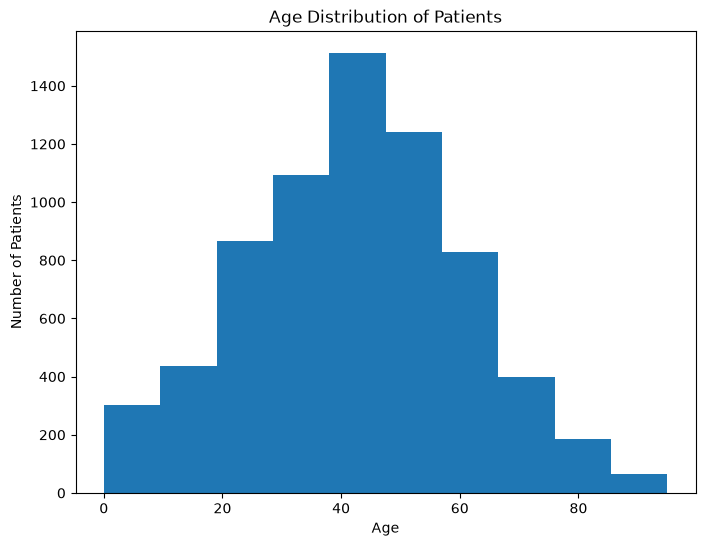

In [52]:
# What is the age distribution of patients?
plt.figure(figsize=(8,6))
plt.hist(df['age'], bins=10)

plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.savefig('age_distribution_of_patients.png')
plt.show()


Age is roughly centered in the 40s, with a fairly even spread
from young children to elderly patients (0–95).
No extreme skew.

The clinic serves a broad age range rather than being concentrated in one group.

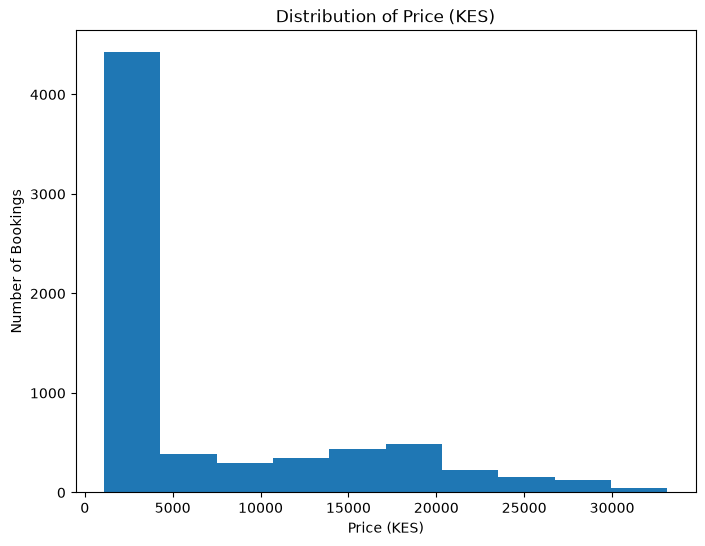

In [53]:
# What's the distribution of price_kes?
plt.figure(figsize=(8,6))
plt.hist(df['price_kes'], bins=10)
plt.title('Distribution of Price (KES)')
plt.xlabel('Price (KES)')
plt.ylabel('Number of Bookings')
plt.savefig('distribution_of_price_kes.png')
plt.show()


This reflects the fact that price is largely driven by modality: a cluster of low values (X-ray/Ultrasound, KES 2,000–4,500)
and a separate cluster of high values (CT/MRI, KES 7,000–32,000).

Price alone isn't a continuous variable here; it's segmented by scan type.

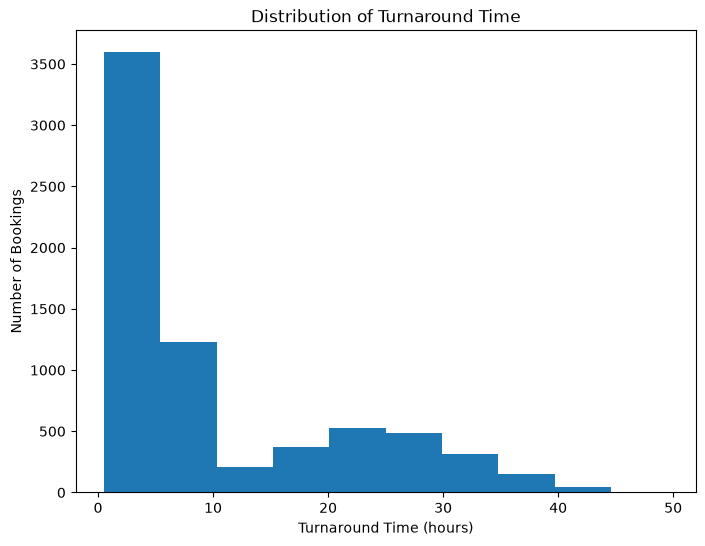

In [54]:
# What's the distribution of turnaround_hours?
plt.figure(figsize=(8,6))
plt.hist(df['turnaround_hours'], bins=10)
plt.title('Distribution of Turnaround Time')
plt.xlabel('Turnaround Time (hours)')
plt.ylabel('Number of Bookings')
plt.savefig('distribution_of_turnaround_time.png')
plt.show()


Most bookings cluster at low turnaround (X-ray/Ultrasound/
Mammography, a few hours), while CT/MRI scans form a separate, much slower cluster(15–30+ hours).

This mirrors the price distribution — modality is the main driver of both cost and speed.

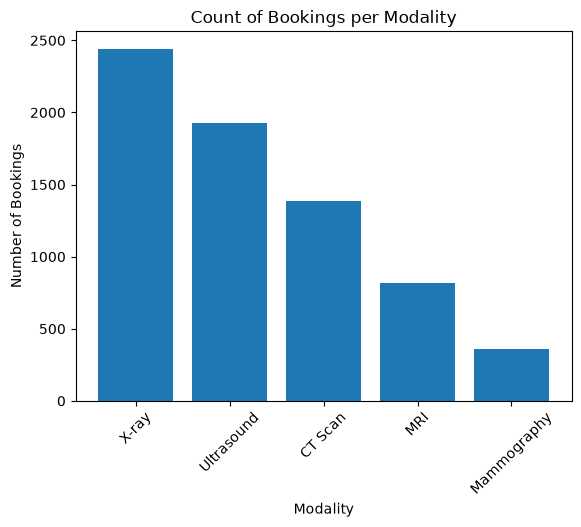

In [55]:
# What's the count of bookings per modality
bookings_per_modality = df.groupby('modality')['booking_id'].count().sort_values(ascending=False)

plt.bar(bookings_per_modality.index, bookings_per_modality.values)
plt.title('Count of Bookings per Modality')
plt.xlabel('Modality')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.savefig('count_of_bookings_per_modality.png')
plt.show()


X-ray is by far the most frequently booked modality, followed by Ultrasound then CT Scan.

MRI and Mammography are comparatively rare — consistent with MRI/Mammography being specialized, lower-volume services while
X-ray/Ultrasound serve as routine, high-throughout scans.

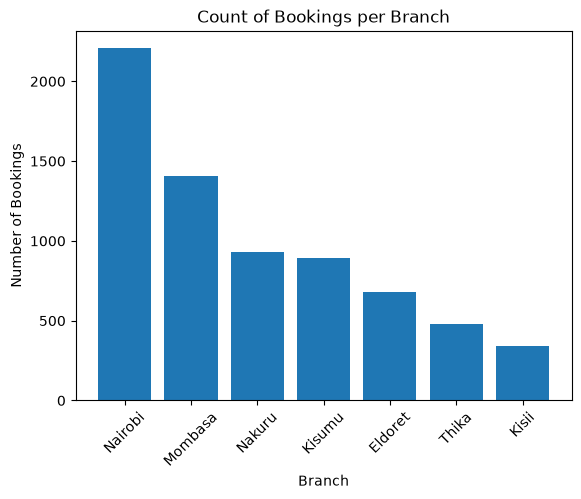

In [56]:
# What's the count of bookings per branch
bookings_per_branch = df.groupby('branch')['booking_id'].count().sort_values(ascending=False)

plt.bar(bookings_per_branch.index, bookings_per_branch.values)
plt.title('Count of Bookings per Branch')
plt.xlabel('Branch')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.savefig('count_of_bookings_per_branch.png')
plt.show()

Nairobi has the highest booking volume by a wide margin, consistent with it being the
largest market. Smaller branches (Kisii, Thika) have noticeably fewer bookings,
reflecting their smaller catchment areas.

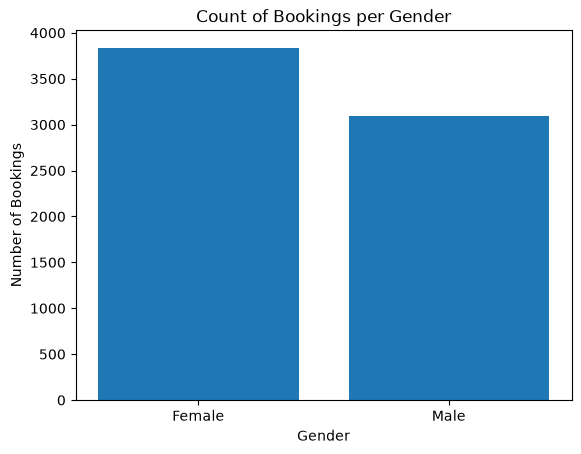

In [57]:
# What's the count of bookings per gender
bookings_per_gender = df.groupby('gender')['booking_id'].count().sort_values(ascending=False)

plt.bar(bookings_per_gender.index, bookings_per_gender.values)
plt.title('Count of Bookings per Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Bookings')
plt.savefig('count_of_bookings_per_gender.png')
plt.show()

The overall gender split is close to balanced, with a slight skew depending on
modality mix at each branch. 

The one clear exception is Mammography,
which is booked almost exclusively by women — as expected for that scan type.

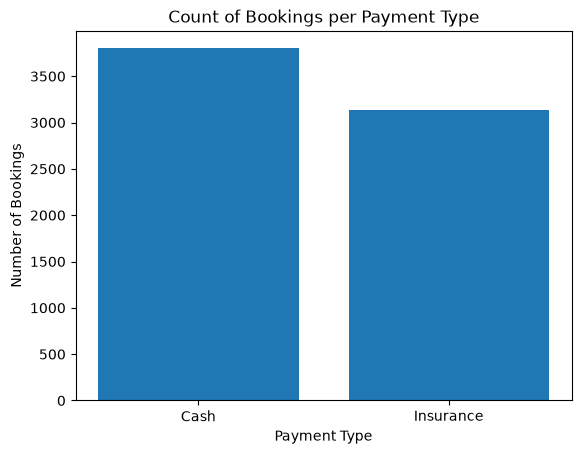

In [58]:
# What's the count of bookings per payment type
bookings_per_payment_type = df.groupby('payment_type')['booking_id'].count().sort_values(ascending=False)

plt.bar(bookings_per_payment_type.index, bookings_per_payment_type.values)
plt.title('Count of Bookings per Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Number of Bookings')
plt.savefig('count_of_bookings_per_payment_type.png')
plt.show()

Cash bookings outnumber Insurance bookings in raw count, but Insurance contributes a
larger share of revenue (53% vs 47%) — consistent with Insurance payments skewing
toward the pricier CT/MRI scans, while Cash dominates the cheaper, high-volume X-ray/
Ultrasound bookings.

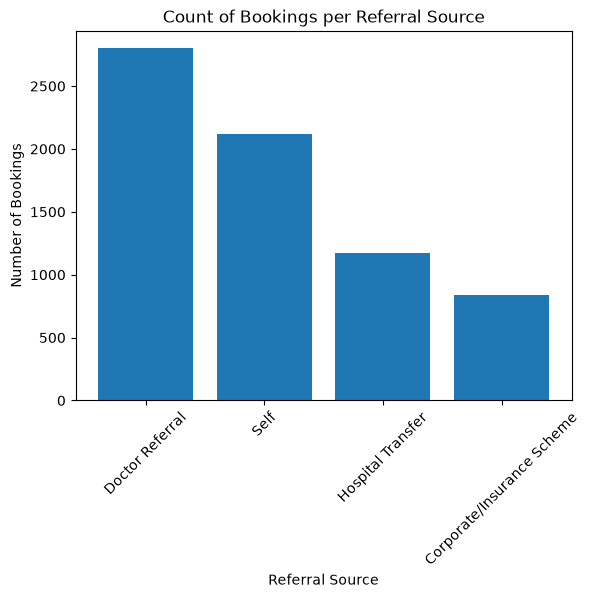

In [59]:
# What's the count of bookings per referral source
bookings_per_referral_source = df.groupby('referral_source')['booking_id'].count().sort_values(ascending=False)

plt.bar(bookings_per_referral_source.index, bookings_per_referral_source.values)
plt.title('Count of Bookings per Referral Source')
plt.xlabel('Referral Source')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.savefig('count_of_bookings_per_referral_source.png')
plt.show()

Doctor Referral and Self-referral are the two largest sources, with Hospital Transfer
and Corporate/Insurance Scheme contributing smaller shares.

This suggests most
patients arrive either through a physician's direct recommendation or by booking on
their own initiative, rather than through formal institutional pipelines.


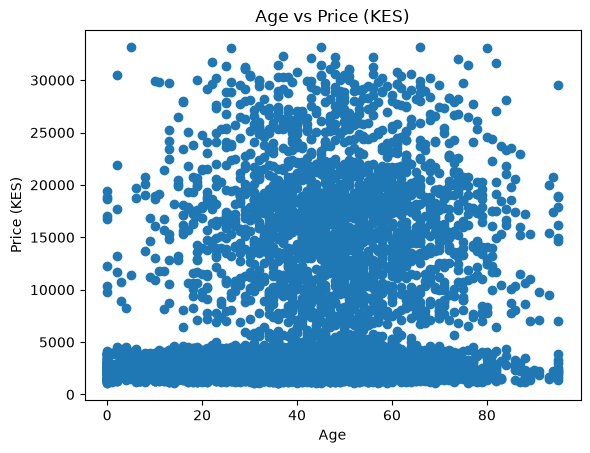

In [60]:
# Is there a relation between age and price_kes?
plt.scatter(df['age'], df['price_kes'])
plt.title('Age vs Price (KES)')
plt.xlabel('Age')
plt.ylabel('Price (KES)')
plt.savefig('age_vs_price_kes.png')
plt.show()


In [61]:
# Is there a relation between age and price_kes?
corr_age_price = df['age'].corr(df['price_kes'])
print(f"Correlation between age and price_kes: {corr_age_price}")


Correlation between age and price_kes: 0.2072108587397533


Correlation is weak but positive (r ≈ 0.21). Age doesn't directly
set the price, but older patients are somewhat more likely to need CT/MRI scans
which cost more, creating an indirect, modest relationship rather than a strong
linear one.

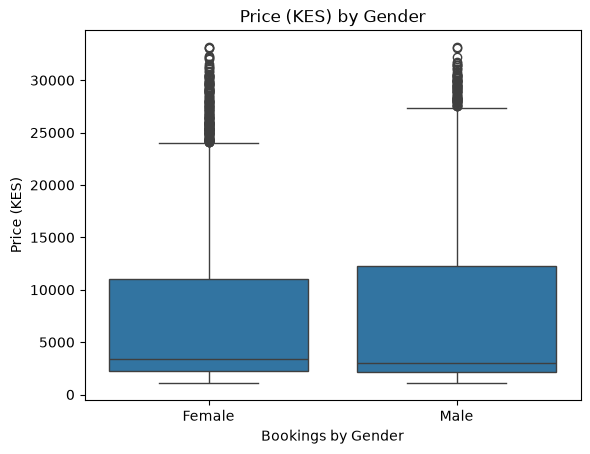

In [62]:
# Does price_kes differ significantly by gender?
sns.boxplot(x='gender', y='price_kes', data=df)
plt.title('Price (KES) by Gender')
plt.xlabel('Bookings by Gender')
plt.ylabel('Price (KES)')
plt.savefig('price_kes_by_gender.png')
plt.show()

Median and spread of price are very similar between Male and Female, with no
meaningful difference in typical cost. This suggests gender itself isn't a driver of
pricing

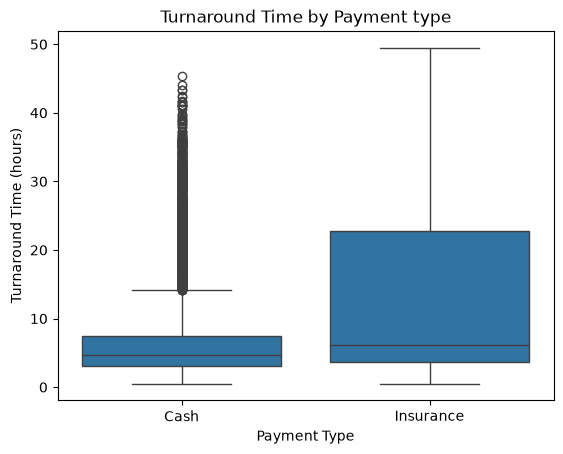

In [63]:
# Does turnaround_hours vary by payment_type
sns.boxplot(x='payment_type', y='turnaround_hours', data=df)
plt.title('Turnaround Time by Payment type')
plt.xlabel('Payment Type')
plt.ylabel('Turnaround Time (hours)')
plt.savefig('turnaround_time_by_payment_type.png')
plt.show()

Insurance-paid bookings show a slightly longer turnaround than Cash on average.

This likely reflects the fact that Insurance
bookings skew toward CT/MRI (which have inherently longer turnaround), rather than
insurance claims processing itself slowing down results.

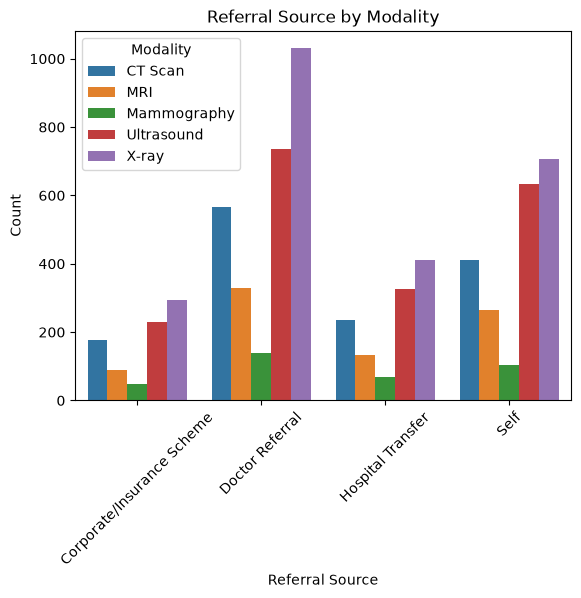

In [64]:
# Is there a relationship between referral_source and modality?
sns.countplot(x='referral_source', hue='modality', data=df)
plt.title('Referral Source by Modality')
plt.xlabel('Referral Source')
plt.ylabel('Count')
plt.legend(title='Modality')
plt.xticks(rotation=45)
plt.savefig('referral_source_by_modality.png')
plt.show()


Doctor Referral is a major source across all modalities, but Corporate/Insurance
Scheme referrals lean more heavily toward CT and MRI — consistent with insurance-
scheme patients being referred for more involved diagnostic imaging rather than
routine X-rays.

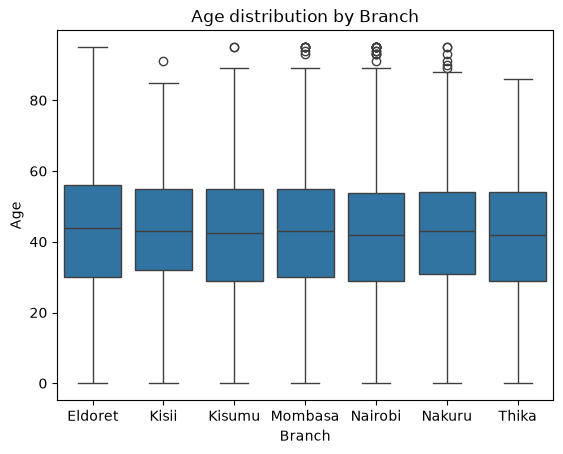

In [65]:
# How does the age distribution differ across branch?
sns.boxplot(x='branch', y='age', data=df)
plt.title('Age distribution by Branch')
plt.xlabel('Branch')
plt.ylabel('Age')
plt.savefig('age_distribution_by_branch.png')
plt.show()


Age distribution is fairly consistent across branches — no single branch serves a
notably older or younger population.

Median age and spread look similar everywhere,
suggesting demographics aren't a major differentiator between locations.

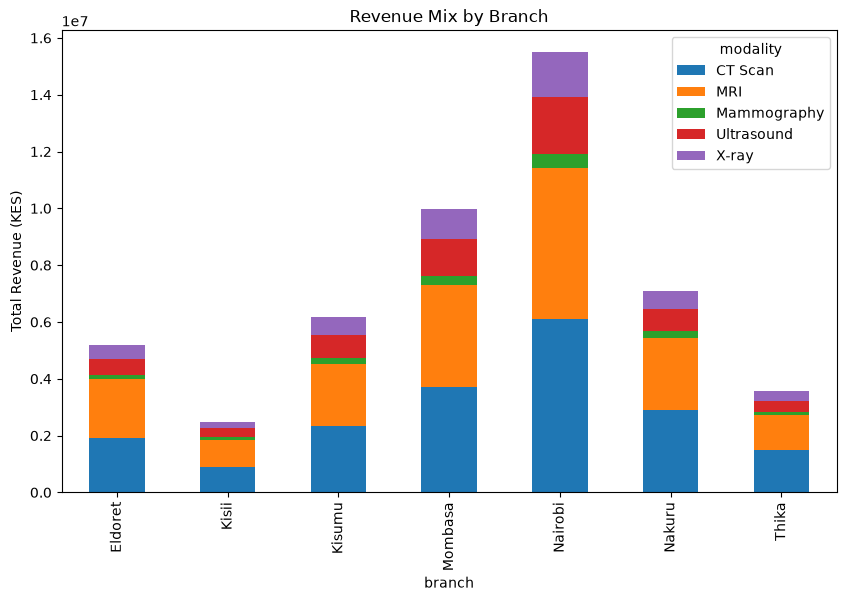

In [66]:
# Does the revenue mix (which modalities are booked) differ by branch?
revenue_mix = df.groupby(['branch', 'modality'])['price_kes'].sum().unstack()

revenue_mix.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title('Revenue Mix by Branch')
plt.ylabel('Total Revenue (KES)')
plt.savefig('revenue_mix_by_branch.png')
plt.show()

Nairobi generates the most total revenue, driven primarily by CT and MRI (the two
most expensive modalities) despite X-ray being its highest-volume service, high
ticket-price scans outweigh the sheer count of cheap ones.

 Smaller branches show a
revenue mix more evenly split across modalities, without one scan type dominating
as clearly.

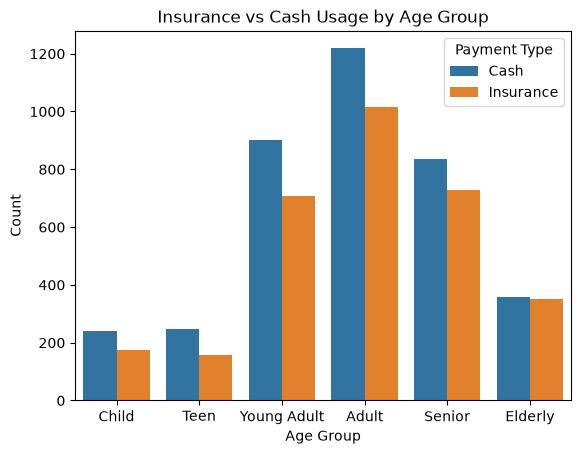

In [67]:
# Do older patients rely more on insurance?
sns.countplot(x='age_group', hue='payment_type', data=df)
plt.title('Insurance vs Cash Usage by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.legend(title='Payment Type')
plt.savefig('insurance_vs_cash_usage_by_age_group.png')
plt.show()

Insurance usage doesn't show a strong age trend — all age groups use a mix of Cash
and Insurance in broadly similar proportions.

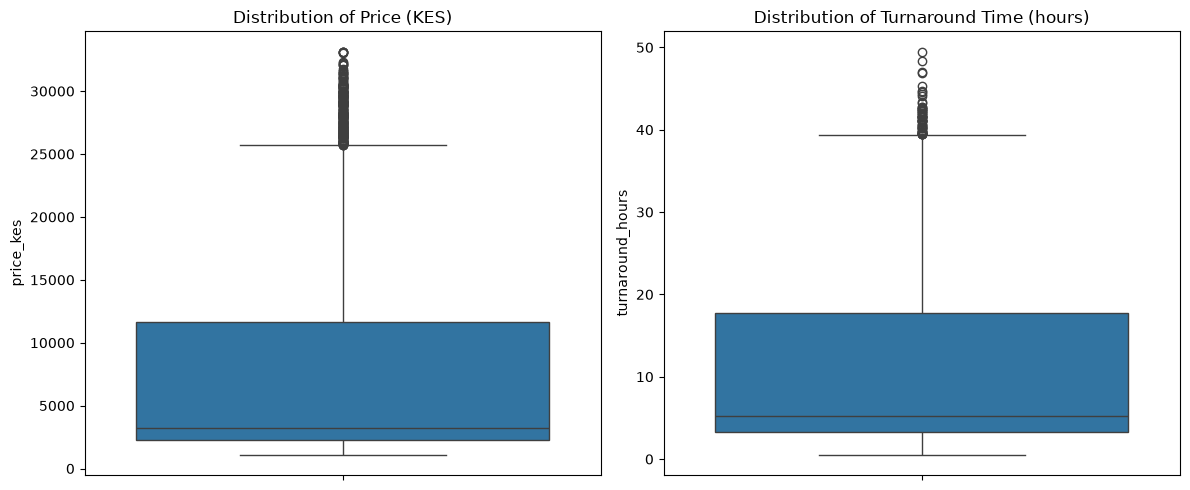

In [68]:
# Outlier Analysis

plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['price_kes'])
plt.title('Distribution of Price (KES)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['turnaround_hours'])
plt.title('Distribution of Turnaround Time (hours)')
plt.tight_layout()
plt.savefig('Distribution.png')
plt.show()

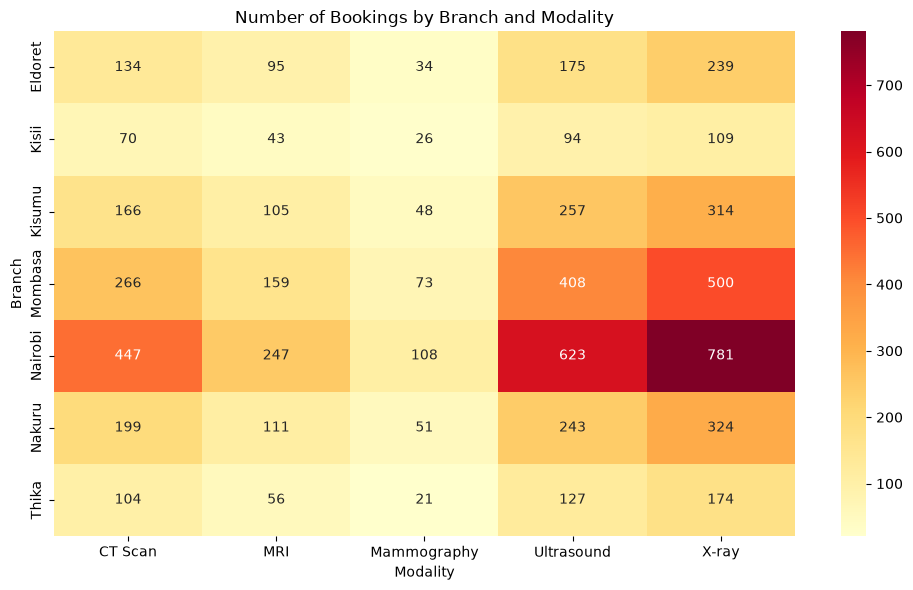

In [69]:
# Do any modality/branch combinations have suspiciously few bookings?
branch_modality_counts = pd.crosstab(df['branch'], df['modality'])

plt.figure(figsize=(10, 6))
sns.heatmap(branch_modality_counts, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Number of Bookings by Branch and Modality')
plt.xlabel('Modality')
plt.ylabel('Branch')
plt.tight_layout()
plt.savefig('branch_modality_heatmap.png')
plt.show()


No branch/modality combination is suspiciously empty — even the smallest branches
(Kisii, Thika) have a reasonable number of bookings for every modality, including
MRI and Mammography. 

This suggests all branches genuinely offer the full range of
services, rather than some combinations being structurally unavailable.

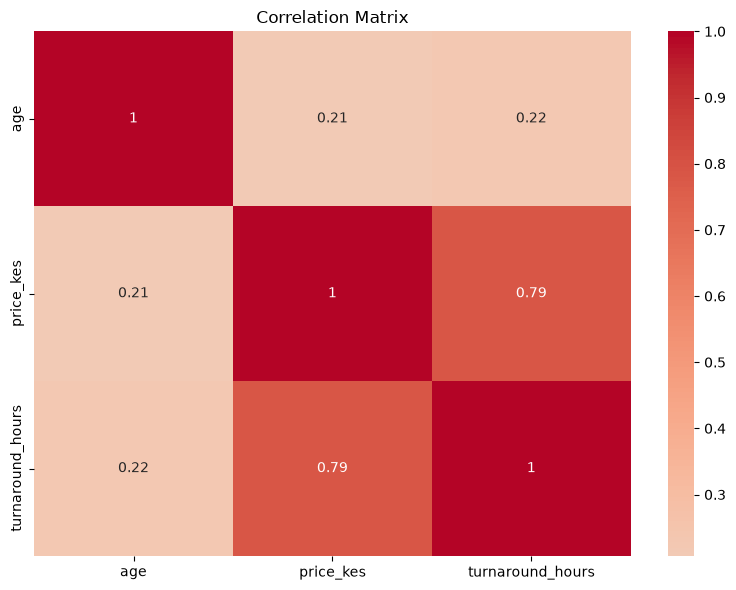

In [70]:
# correlation matrix/heatmap for the numeric columns (age, price_kes, turnaround_hours)
correlation_matrix = df[['age', 'price_kes', 'turnaround_hours']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()


Price_kes and turnaround_hours are strongly positively correlated — expected, since
both are driven by the same underlying factor (modality: CT/MRI are both expensive
and slow). 

Age correlates weakly with both, reflecting only an indirect link through
which modality older patients tend to book.

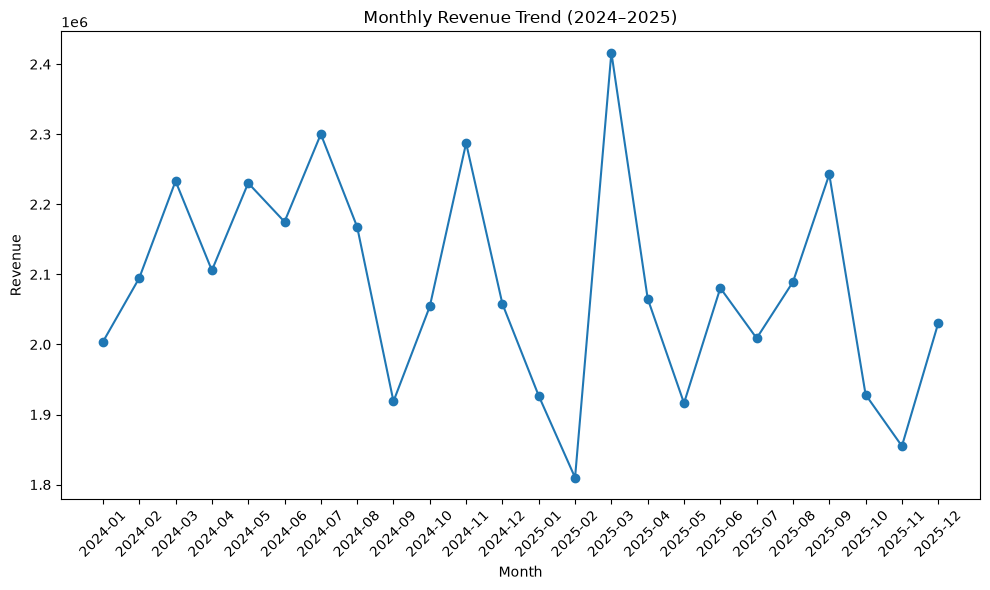

In [71]:
# Monthly revenue trend (2024–2025)
plt.figure(figsize=(10, 6))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker='o')
plt.title('Monthly Revenue Trend (2024–2025)')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_revenue_trend.png')
plt.show()

Revenue fluctuates month to month without a strong seasonal pattern, consistent with
the earlier finding of roughly flat seasonality by season/month. Overall revenue is
down about 4.9% from 2024 to 2025 — a mild decline rather than a sharp drop, so this
likely reflects a gradual trend rather than one bad month.

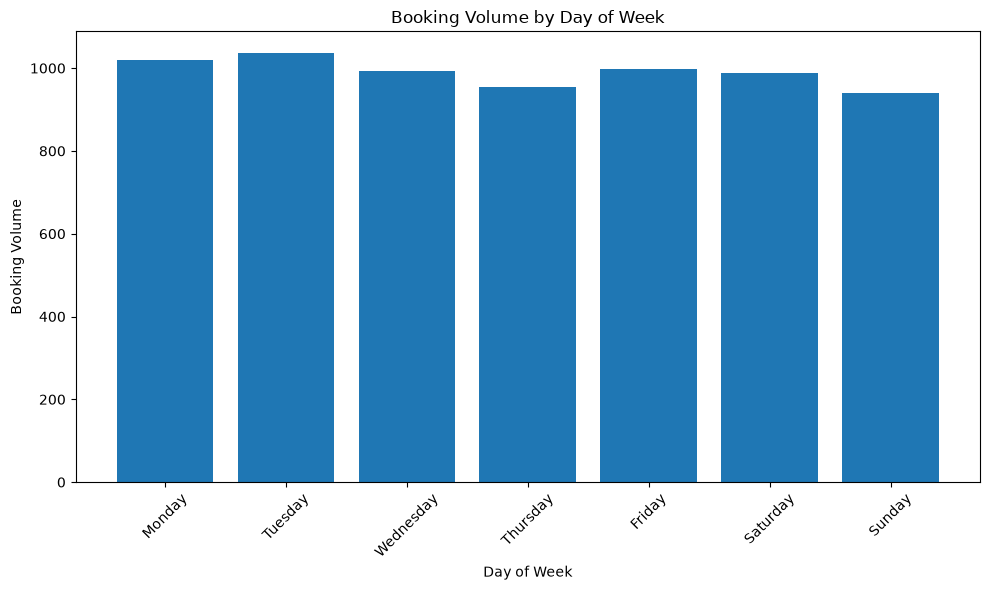

In [72]:
# Booking volume by day-of-week
booking_volume_by_day = df.groupby('scan_day_of_week')['booking_id'].count().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

plt.figure(figsize=(10, 6))
plt.bar(booking_volume_by_day.index, booking_volume_by_day.values)
plt.title('Booking Volume by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Booking Volume')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('booking_volume_by_day.png')
plt.show()


Weekday bookings slightly outnumber weekend bookings, with Tuesday the busiest day
and Sunday the quietest — but the difference across all seven days is fairly small,
suggesting demand is spread fairly evenly through the week rather than being heavily
weekday-concentrated.

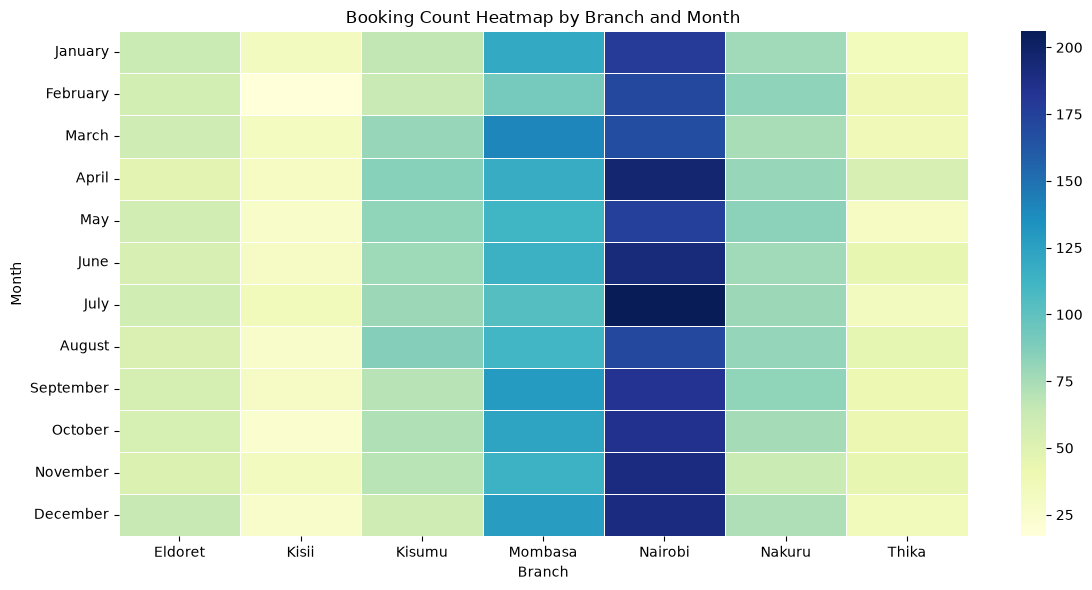

In [73]:
# Groupby and Multi-level Analysis
# Create a heatmap of sales by month and branch

month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

heatmap_data =(
    df.pivot_table(
        values='booking_id',
        index='scan_month',
        columns='branch',
        aggfunc='count',   
    ).reindex(month_order)   
)

plt.figure(figsize=(12, 6))  
sns.heatmap(heatmap_data, annot=False, cmap='YlGnBu', linewidths=0.5)
plt.title('Booking Count Heatmap by Branch and Month')
plt.xlabel('Branch')
plt.ylabel('Month')
plt.tight_layout()
plt.savefig('booking_count_heatmap.png')
plt.show()


Nairobi dominates. It runs roughly 80 to 100 bookings per month, with clear peaks in July and October. It is the only branch with a visible spike.

Mombasa is a clear second, at about 50 to 70 per month and fairly steady. It looks strongest in January and March.

Kisumu and Nakuru sit in the middle, around 25 to 50, with Nakuru a bit higher in February, May and September.

Eldoret and Thika are low and flat, around 20 to 35.

Kisii is the weakest, at about 10 to 20 every month, and lowest in February and August.

In [74]:
# Interactive Visualization (Plotly)
# Monthly revenue trend (interactive)

monthly = (
    df.groupby(df['scan_date'].dt.to_period('M'))['price_kes'].sum().reset_index())
monthly['scan_date'] = monthly['scan_date'].dt.to_timestamp()   
 
fig = px.line(
    monthly, x='scan_date', y='price_kes', markers=True,
    title='Monthly Revenue Trend (2024-2025)',
    labels={'scan_date': 'Month', 'price_kes': 'Revenue (KES)'}
)
fig.update_layout(hovermode='x unified')
plt.savefig('interactive_monthly_revenue_trend.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [75]:
# Revenue per branch
branch_rev = (
    df.groupby('branch', observed=True)['price_kes'].sum().sort_values(ascending=False).reset_index())
 
fig = px.bar(
    branch_rev, x='branch', y='price_kes', text_auto='.2s',
    title='Total Revenue by Branch',
    labels={'branch': 'Branch', 'price_kes': 'Revenue (KES)'}
)
plt.savefig('total_revenue_by_branch.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [76]:
# 4. Revenue by branch, split by modality 
rev_mix = df.groupby(['branch', 'modality'], observed=True)['price_kes'].sum().reset_index()
 
fig = px.bar(
    rev_mix, x='branch', y='price_kes', color='modality', barmode='stack',
    title='Revenue Mix by Branch and Modality',
    labels={'branch': 'Branch', 'price_kes': 'Revenue (KES)', 'modality': 'Modality'}
)
plt.savefig('revenue_mix_by_branch_modality.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [77]:
# Monthly revenue per branch
branch_month = (df.groupby([df['scan_date'].dt.to_period('M'), 'branch'], observed=True)['price_kes'].sum().reset_index())
branch_month['scan_date'] = branch_month['scan_date'].dt.to_timestamp()
 
fig = px.line(
    branch_month, x='scan_date', y='price_kes', color='branch',
    title='Monthly Revenue by Branch',
    labels={'scan_date': 'Month', 'price_kes': 'Revenue (KES)', 'branch': 'Branch'}
)
fig.update_layout(hovermode='x unified')
plt.savefig('monthly_revenue_by_branch.png')
fig.show()

<Figure size 640x480 with 0 Axes>

### Recommendations
1.  Protect and grow CT and MRI, especially at Nairobi. Nairobi leads in revenue, driven mainly by CT and MRI. Confirm that machine capacity and radiologist availability at Nairobi can absorb more CT/MRI demand, and consider promoting these services to doctor-referral and insurance-scheme sources, which skew toward them.

2. Review the Kisii and Thika branches. Kisii is consistently the weakest branch (roughly 10-20 bookings a month, with no real peak) and Thika is low and flat. Check whether the cause is limited catchment, low awareness or lack of doctor referrals. Referral partnerships with nearby clinics and hospitals.

3. Learn from Eldoret's high revenue per booking. Eldoret has a small volume but a high average price per booking. Find out why (a richer CT/MRI mix, or more insurance patients) and whether another branch can copy the model.

4. Fix turnaround time at Nakuru and for CT/MRI. Nakuru has the slowest average turnaround, and CT/MRI take about 24 hours against about 4 for other scans. Check whether Nakuru's delay is a staffing or reporting bottleneck.

5. Balance the payment mix. Insurance brings in about 53% of revenue and cash the other 47%, while cash bookings are more numerous. Insurance patients pay more because they use CT/MRI more, so watch claim payment delays and keep strong relationships with insurers, while keeping cash-friendly pricing for X-ray and ultrasound.

In [78]:
# Features and target
features = ['modality', 'branch', 'payment_type', 'referral_source', 'gender', 'age', 'is_weekend']
X = pd.get_dummies(df[features], drop_first=True).astype(float)
y = df['price_kes']

In [79]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [80]:
# Fit and evaluate
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(f"MAE : {mean_absolute_error(y_test, pred):,.2f} KES")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):,.2f} KES")
print(f"R2  : {r2_score(y_test, pred):.2f}")

MAE : 1,589.83 KES
RMSE: 2,539.20 KES
R2  : 0.89


modality_X-ray                      -12098.8
modality_Ultrasound                 -10933.0
modality_Mammography                 -9772.5
payment_type_Insurance                -668.1
branch_Kisumu                         -196.0
branch_Kisii                          -163.2
branch_Nairobi                         -79.5
is_weekend                             -25.9
age                                     -1.9
gender_Male                             30.9
referral_source_Doctor Referral         66.5
branch_Mombasa                          84.1
referral_source_Self                   185.5
branch_Thika                           190.3
referral_source_Hospital Transfer      190.7
branch_Nakuru                          246.4
modality_MRI                          7923.3
dtype: float64


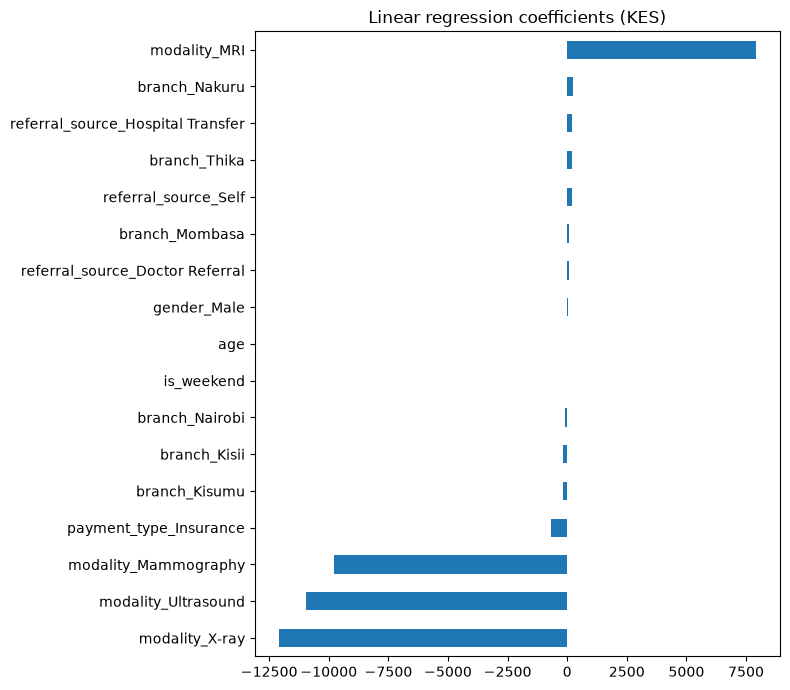

In [81]:
# Coefficients
coefs = pd.Series(model.coef_, index=X.columns).sort_values()
print(coefs.round(1))
coefs.plot(kind='barh', figsize=(8, 7), title='Linear regression coefficients (KES)')
plt.tight_layout()
plt.show()

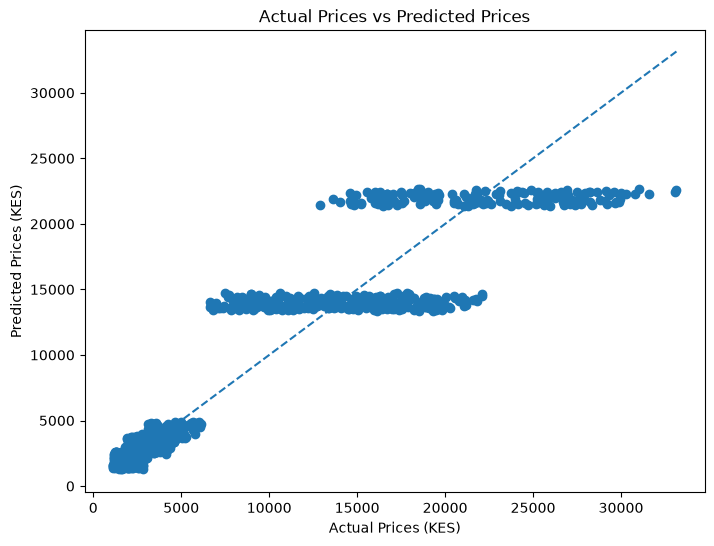

In [82]:
# visualise actual versus predicted prices
plt.figure(figsize=(8,6))
plt.scatter(y_test, pred)

# reference line for perfect predictions
min_value = min(y_test.min(), pred.min())
max_value = max(y_test.max(), pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
    )

plt.xlabel('Actual Prices (KES)')
plt.ylabel('Predicted Prices (KES)')
plt.title('Actual Prices vs Predicted Prices')
plt.show()

### The model explains about 89% of the variation in price. On average, its predictions are off by about KES 1,590.

#### Key findings
1. **Modality drives price.** Compared with CT Scan, MRI is about KES 7,900 higher, while X-ray, Ultrasound and Mammography are about KES 12,100, 10,900 and 9,800 lower.
2. **Other features add little.** A modality-only model gives the same R² (0.887), so branch, referral source, gender, age and weekend make no meaningful difference to price.
3. **Insurance is the one small extra effect.** Insurance bookings are about KES 670 cheaper than cash, holding everything else equal.
4. **Branch effects are small.** Most branch coefficients are under KES 250, so prices are fairly standard across branches. Differences in branch revenue come from the mix of scans, not from pricing.


**Actual vs predicted plot:** Points form vertical clusters by modality instead of hugging the diagonal. Every booking of the same scan type gets almost the same predicted price, while actual prices vary around it. The spread is much wider for CT and MRI (about KES 4,000 to 5,000 standard deviation) than for X-ray, Ultrasound and Mammography (under KES 1,000).

In [83]:
X.columns

Index(['age', 'is_weekend', 'modality_MRI', 'modality_Mammography',
       'modality_Ultrasound', 'modality_X-ray', 'branch_Kisii',
       'branch_Kisumu', 'branch_Mombasa', 'branch_Nairobi', 'branch_Nakuru',
       'branch_Thika', 'payment_type_Insurance',
       'referral_source_Doctor Referral', 'referral_source_Hospital Transfer',
       'referral_source_Self', 'gender_Male'],
      dtype='str')